In [ ]:
# #!/usr/bin/env python3
# import json
# from pathlib import Path
# from typing import Any

# TEMPLATE = Path("/Users/yashturkar/Workspace/3DQualMetrics/Config/round_0.json")
# OUTPUT_DIR = TEMPLATE.parent  # same folder as the template
# ROUNDS = list(range(5, 50, 5))  # 5,10,...,45


# def replace_in_obj(obj: Any, src: str, dst: str) -> Any:
#     """
#     Recursively replace substring `src` with `dst` in all string values
#     within a JSON-serializable object.
#     """
#     if isinstance(obj, dict):
#         return {k: replace_in_obj(v, src, dst) for k, v in obj.items()}
#     if isinstance(obj, list):
#         return [replace_in_obj(v, src, dst) for v in obj]
#     if isinstance(obj, str):
#         return obj.replace(src, dst)
#     return obj  # numbers, bools, None


# def main():
#     if not TEMPLATE.exists():
#         raise FileNotFoundError(f"Template not found: {TEMPLATE}")

#     with TEMPLATE.open("r") as f:
#         template_data = json.load(f)

#     for n in ROUNDS:
#         src = "round_0"
#         src_before = "0_before"
#         src_after = "0_after"
#         dst_before = f"{n}_before"
#         dst_after = f"{n}_after"
#         dst = f"round_{n}"

#         data_n = replace_in_obj(template_data, src, dst)
#         data_n = replace_in_obj(data_n, src_before, dst_before)
#         data_n = replace_in_obj(data_n, src_after, dst_after)
#         out_path = OUTPUT_DIR / f"round_{n}.json"

#         with out_path.open("w") as f:
#             json.dump(data_n, f, indent=4)
#             f.write("\n")

#         print(f"Wrote {out_path}")

# if __name__ == "__main__":
#     main()

Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_5.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_10.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_15.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_20.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_25.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_30.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_35.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_40.json
Wrote /Users/yashturkar/Workspace/3DQualMetrics/Config/round_45.json


In [7]:
# %% Aggregate artifact metrics across rounds and compute per-intensity means

import os, json, glob
from collections import defaultdict, OrderedDict
import numpy as np
import pandas as pd

# ====== CONFIG ======
RESULTS_ROOT = "./results"                    # root folder that contains round_0, round_5, ..., round_45
ROUNDS = list(range(0, 50, 5))                # 0,5,10,...,45
PATTERN = "artifact_*after*.json"             # only artifact "after" files

# ====== HELPERS ======
def to_decimal_from_zeros(token: str) -> float:
    """
    Convert tokens like '01','0001','005','0005','1','10' to decimals
    by placing a decimal before the LAST digit:
      '01'   -> 0.1
      '0001' -> 0.001
      '005'  -> 0.05
      '0005' -> 0.005
      '1'    -> 1.0
      '10'   -> 1.0  (10 / 10^(2-1))
    If token already has a '.', just float() it.
    """
    token = token.strip()
    if "." in token:
        return float(token)
    if not token.isdigit():
        raise ValueError(f"Non-numeric token: {token}")
    n = len(token)
    return int(token) / (10 ** (n - 1)) if n > 1 else float(token)

def intensity_from_result_filename(fname: str):
    """
    Expect names like:
      artifact_01_002_0_after_size_...json
      artifact_0005_002_0_after_size_...json
    Grab the first numeric token after 'artifact_' and convert it.
    """
    base = os.path.basename(fname)
    if not base.lower().startswith("artifact_"):
        return None
    parts = base.split("_")
    if len(parts) < 2:
        return None
    return to_decimal_from_zeros(parts[1])

def get_measured_artifacts(payload: dict):
    """
    Pull measured average artifacts from common locations.
    Here we expect payload["average"]["artifacts"] to exist.
    Return float or None.
    """
    avg = payload.get("average")
    if isinstance(avg, dict) and "artifacts" in avg:
        return float(avg["artifacts"])
    return None

# ====== COLLECT ======
# temp structure: for each intensity, store {round_number: measured_value}
per_intensity_by_round = defaultdict(dict)

for n in ROUNDS:
    round_dir = os.path.join(RESULTS_ROOT, f"round_{n}")
    for path in glob.glob(os.path.join(round_dir, PATTERN)):
        try:
            with open(path, "r") as f:
                data = json.load(f)
        except Exception:
            continue

        measured = get_measured_artifacts(data)
        if measured is None:
            continue

        intensity = intensity_from_result_filename(path)
        if intensity is None:
            continue

        per_intensity_by_round[intensity][n] = measured

# ====== ALIGN INTO LISTS (one value per round, NaN if missing) ======
# Sort intensities for a stable order
sorted_intensities = sorted(per_intensity_by_round.keys())

values_by_intensity = OrderedDict()
for intensity in sorted_intensities:
    round_map = per_intensity_by_round[intensity]
    # list aligned to ROUNDS order; np.nan for missing rounds
    aligned = [round_map.get(n, np.nan) for n in ROUNDS]
    values_by_intensity[intensity] = aligned

# ====== MEANS (ignoring missing) ======
means_by_intensity = {
    intensity: float(np.nanmean(vals)) if np.any(~np.isnan(vals)) else np.nan
    for intensity, vals in values_by_intensity.items()
}

# ====== OUTPUT ======
# 1) Dict of values per intensity (aligned to ROUNDS)
print("ROUNDS:", ROUNDS)
print("values_by_intensity (lists correspond to ROUNDS order):")
for intensity, vals in values_by_intensity.items():
    print(f"  {intensity}: {vals}")

# 2) Means over rounds
print("\nmeans_by_intensity:")
for intensity, m in means_by_intensity.items():
    print(f"  {intensity}: {m}")

# Optional: nice DataFrame views
df_values = pd.DataFrame(values_by_intensity, index=ROUNDS)
df_values.index.name = "round"
df_means = pd.Series(means_by_intensity, name="mean_over_rounds").to_frame()

print("\nPer-round values table:\n", df_values)
print("\nMeans table:\n", df_means)

ROUNDS: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45]
values_by_intensity (lists correspond to ROUNDS order):
  0.001: [0.9724707501720579, 0.9732620320855615, 0.9637482900136799, 0.9653652392947103, 0.9662698412698413, 0.9671558350803634, 0.9685929648241206, 0.9735772357723578, 0.9701591511936339, 0.9645535105657805]
  0.005: [0.9618788291354663, 0.9894235854045479, 0.9826435246995995, 0.9896707553260168, 0.9773869346733668, 0.9780918727915194, 0.9685929648241206, 0.9769021739130435, 0.9785953177257525, 0.9782894736842105]
  0.05: [0.8890251379521765, 0.8763906056860321, 0.8940355329949239, 0.8331521739130434, 0.8741573033707866, 0.8799755052051439, 0.8576122672508215, 0.8564535585042219, 0.8388761467889908, 0.8633811603243917]
  0.1: [0.7630306286942504, 0.7634464751958224, 0.7452731092436975, 0.7438400743840075, 0.7483091787439613, 0.7797427652733119, 0.767200754005655, 0.7394871794871796, 0.7522343594836147, 0.7504970178926441]

means_by_intensity:
  0.001: 0.9685154850272106
  0.005: 0.9

                      Artifact Degradation  Success Rate %  \
Artifact Degradation                   1.0             0.8   
Success Rate %                         0.8             1.0   
Artifact Score (E3D)                   0.8             1.0   

                      Artifact Score (E3D)  
Artifact Degradation                   0.8  
Success Rate %                         1.0  
Artifact Score (E3D)                   1.0  


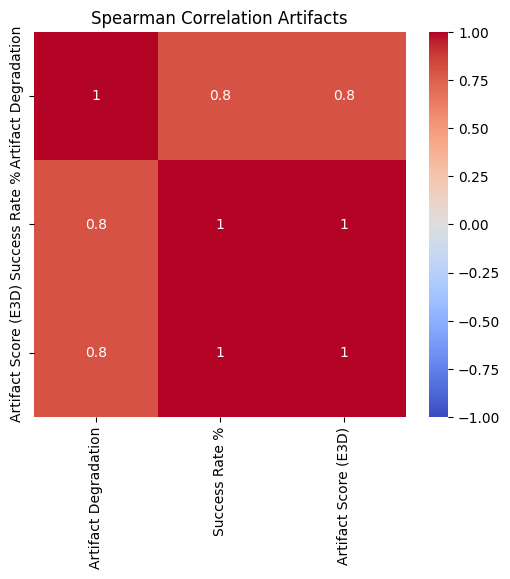

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

artifact_intensities = np.array([0.005, 0.001, 0.05, 0.1])
artifact_intensities = 1 - artifact_intensities  # Invert to match bar chart


# from bar chart
measured_values = np.array([29.2, 28.125, 23.293172690763054, 20.689655172413794])

# from JSON results
# measured_artifacts = np.array([0.961879, 0.972471, 0.889025, 0.763031])

# mean over all rounds
measured_artifacts = np.array([0.978148, 0.968515, 0.866306, 0.755306])


# put into DataFrame
df = pd.DataFrame({
    "Artifact Degradation": artifact_intensities,
    "Success Rate %": measured_values,
    "Artifact Score (E3D)": measured_artifacts
})

# compute Spearman correlation matrix
corr_matrix = df.corr(method="spearman")
print(corr_matrix)

# plot heatmap
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation Artifacts")
plt.show()

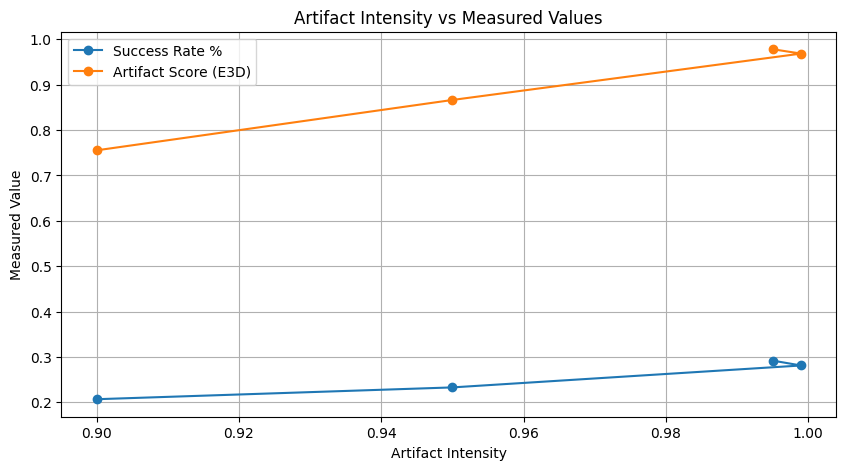

In [34]:
artifact_intensities = np.array([0.005, 0.001, 0.05, 0.1])
artifact_intensities = 1 - artifact_intensities  # Invert to match bar chart


# from bar chart
measured_values = np.array([29.2, 28.125, 23.293172690763054, 20.689655172413794]) 

# normalize to 0-100 
measured_values = measured_values / 100   # Normalize to 0-100

# from JSON results
# measured_artifacts = np.array([0.961879, 0.972471, 0.889025, 0.763031])

# mean over all rounds
measured_artifacts = np.array([0.978148, 0.968515, 0.866306, 0.755306])

# Plot line plots where artifact_intensities are on X axis and other two are Y axes 
plt.figure(figsize=(10, 5))
plt.plot(artifact_intensities, measured_values, marker='o', label='Success Rate %')
plt.plot(artifact_intensities, measured_artifacts, marker='o', label='Artifact Score (E3D)')
plt.xlabel('Artifact Intensity')
plt.ylabel('Measured Value')
plt.title('Artifact Intensity vs Measured Values')
plt.legend()
plt.grid()
plt.show()

In [25]:
# %% Aggregate metrics (artifacts, coverage_{X,Y,Z}, accuracy[noise], resolution) across rounds

import os, re, glob, json
from collections import defaultdict, OrderedDict
import numpy as np
import pandas as pd

# ----------------- CONFIG -----------------
RESULTS_ROOT = "./results"           # contains round_0, round_5, ..., round_45
ROUNDS = list(range(0, 50, 5))       # 0,5,10,...,45
ONLY_AFTER = True
FILE_GLOB = "*.json"                 # we will filter to "*after*" in code if ONLY_AFTER is True

# ----------------- HELPERS -----------------
def to_decimal_from_zeros(token: str) -> float:
    token = token.strip()
    if "." in token:
        return float(token)
    if not token.isdigit():
        raise ValueError(f"Non-numeric token: {token}")
    n = len(token)
    return int(token) / (10 ** (n - 1)) if n > 1 else float(token)

re_artifact   = re.compile(r"^artifact_([^_]+)_",         re.IGNORECASE)
re_accuracy   = re.compile(r"^noise_([^_]+)_",            re.IGNORECASE)  # NOTE: noise filename => accuracy metric
re_resolution = re.compile(r"^resolution_([^_]+)_",       re.IGNORECASE)
re_coverage   = re.compile(r"^coverage_([^_]+)_([XYZ])_", re.IGNORECASE)

def parse_metric_and_intensity(fname: str):
    """
    Returns (metric_name, intensity_key) or (None, None).
    metric_name ∈ {'artifacts','coverage_X','coverage_Y','coverage_Z','accuracy','resolution'}.
    """
    base = os.path.basename(fname)
    if ONLY_AFTER and "after" not in base.lower():
        return None, None

    m = re_artifact.match(base)
    if m:
        return "artifacts", to_decimal_from_zeros(m.group(1))

    m = re_accuracy.match(base)  # filenames with 'noise_' -> accuracy metric
    if m:
        return "accuracy", to_decimal_from_zeros(m.group(1))

    m = re_resolution.match(base)
    if m:
        return "resolution", to_decimal_from_zeros(m.group(1))

    m = re_coverage.match(base)
    if m:
        inten = to_decimal_from_zeros(m.group(1))
        axis = m.group(2).upper()
        return f"coverage_{axis}", f"{inten}_{axis}"

    return None, None

def get_metric_value_from_json(payload: dict, metric_name: str):
    """
    Reads payload['average'][key].
    coverage_{X,Y,Z} -> use 'coverage'
    accuracy (from 'noise' filenames) -> use 'accuracy'
    """
    avg = payload.get("average")
    if not isinstance(avg, dict):
        return None

    if metric_name.startswith("coverage_"):
        key = "coverage"
    elif metric_name == "accuracy":
        key = "accuracy"
    else:
        key = metric_name  # 'artifacts' or 'resolution'

    val = avg.get(key)
    return float(val) if isinstance(val, (int, float)) else None

# ----------------- COLLECT -----------------
per_metric = defaultdict(lambda: defaultdict(dict))  # metric -> intensity_key -> round -> value

for n in ROUNDS:
    round_dir = os.path.join(RESULTS_ROOT, f"round_{n}")
    for path in glob.glob(os.path.join(round_dir, FILE_GLOB)):
        base = os.path.basename(path)
        if ONLY_AFTER and "after" not in base.lower():
            continue

        metric_name, intensity_key = parse_metric_and_intensity(base)
        if metric_name is None:
            continue

        try:
            with open(path, "r") as f:
                payload = json.load(f)
        except Exception:
            continue

        val = get_metric_value_from_json(payload, metric_name)
        if val is None:
            continue

        per_metric[metric_name][intensity_key][n] = val

# ----------------- ALIGN + MEANS -----------------
values_by_metric = {}
means_by_metric_intensity = {}
overall_mean_by_metric = {}

def _sort_key(k):
    if isinstance(k, (int, float)):
        return (float(k), "")
    if isinstance(k, str) and "_" in k:
        num, axis = k.split("_", 1)
        try:
            return (float(num), axis)
        except:
            return (num, axis)
    return (k, "")

for metric_name, by_intensity in per_metric.items():
    ordered_intensities = sorted(by_intensity.keys(), key=_sort_key)

    metric_map = OrderedDict()
    metric_means = OrderedDict()
    all_vals_for_metric = []

    for ik in ordered_intensities:
        round_map = by_intensity[ik]
        aligned = [round_map.get(n, np.nan) for n in ROUNDS]
        metric_map[ik] = aligned

        m = float(np.nanmean(aligned)) if np.any(~np.isnan(aligned)) else np.nan
        metric_means[ik] = m
        all_vals_for_metric.extend([v for v in aligned if not np.isnan(v)])

    values_by_metric[metric_name] = metric_map
    means_by_metric_intensity[metric_name] = metric_means
    overall_mean_by_metric[metric_name] = float(np.mean(all_vals_for_metric)) if all_vals_for_metric else np.nan

# ----------------- OUTPUT -----------------
print("ROUNDS:", ROUNDS)

print("\nvalues_by_metric (lists align to ROUNDS):")
for metric, mp in values_by_metric.items():
    print(f"\n[{metric}]")
    for ik, lst in mp.items():
        print(f"  {ik}: {lst}")

print("\nmeans_by_metric_intensity:")
for metric, mp in means_by_metric_intensity.items():
    print(f"\n[{metric}]")
    for ik, m in mp.items():
        print(f"  mean({ik}) over rounds = {m}")

print("\noverall_mean_by_metric (6 metrics total):")
for metric, m in overall_mean_by_metric.items():
    print(f"  {metric}: {m}")

# Optional: DataFrames if you want tables
tables = {}
for metric, mp in values_by_metric.items():
    df_values = pd.DataFrame(mp, index=ROUNDS)
    df_values.index.name = "round"
    tables[metric] = df_values
# e.g., tables["accuracy"]  # values for the metric formerly labeled "noise"

ROUNDS: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45]

values_by_metric (lists align to ROUNDS):

[artifacts]
  0.001: [0.9724707501720579, 0.9732620320855615, 0.9637482900136799, 0.9653652392947103, 0.9662698412698413, 0.9671558350803634, 0.9685929648241206, 0.9735772357723578, 0.9701591511936339, 0.9645535105657805]
  0.005: [0.9618788291354663, 0.9894235854045479, 0.9826435246995995, 0.9896707553260168, 0.9773869346733668, 0.9780918727915194, 0.9685929648241206, 0.9769021739130435, 0.9785953177257525, 0.9782894736842105]
  0.05: [0.8890251379521765, 0.8763906056860321, 0.8940355329949239, 0.8331521739130434, 0.8741573033707866, 0.8799755052051439, 0.8576122672508215, 0.8564535585042219, 0.8388761467889908, 0.8633811603243917]
  0.1: [0.7630306286942504, 0.7634464751958224, 0.7452731092436975, 0.7438400743840075, 0.7483091787439613, 0.7797427652733119, 0.767200754005655, 0.7394871794871796, 0.7522343594836147, 0.7504970178926441]

[coverage_Y]
  0.4_Y: [0.3474876150035386, 0.369108049311095


Spearman Correlation: Artifacts
                        Artifacts Degradation  Success Rate %  \
Artifacts Degradation                    1.0             0.8   
Success Rate %                           0.8             1.0   
Artifacts Score (E3D)                    0.8             1.0   

                       Artifacts Score (E3D)  
Artifacts Degradation                    0.8  
Success Rate %                           1.0  
Artifacts Score (E3D)                    1.0  


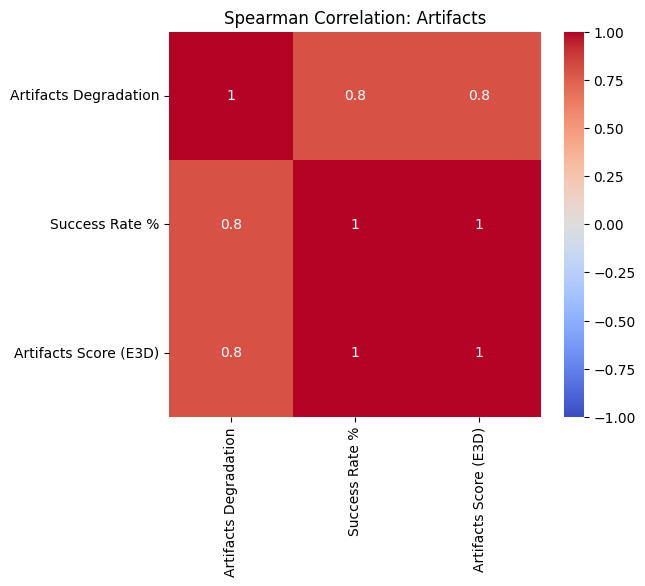


Spearman Correlation: Coverage X
                         Coverage X Degradation  Success Rate %  \
Coverage X Degradation                     1.0             0.8   
Success Rate %                             0.8             1.0   
Coverage X Score (E3D)                     1.0             0.8   

                        Coverage X Score (E3D)  
Coverage X Degradation                     1.0  
Success Rate %                             0.8  
Coverage X Score (E3D)                     1.0  


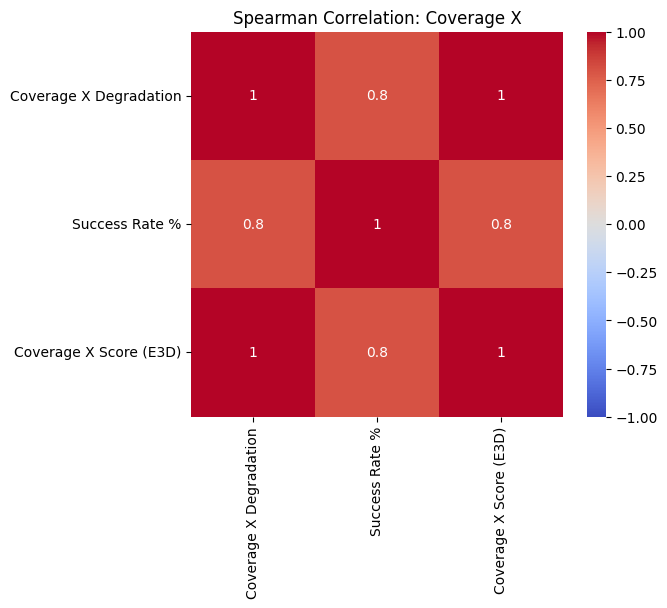


Spearman Correlation: Coverage Y
                         Coverage Y Degradation  Success Rate %  \
Coverage Y Degradation                     1.0             0.4   
Success Rate %                             0.4             1.0   
Coverage Y Score (E3D)                     1.0             0.4   

                        Coverage Y Score (E3D)  
Coverage Y Degradation                     1.0  
Success Rate %                             0.4  
Coverage Y Score (E3D)                     1.0  


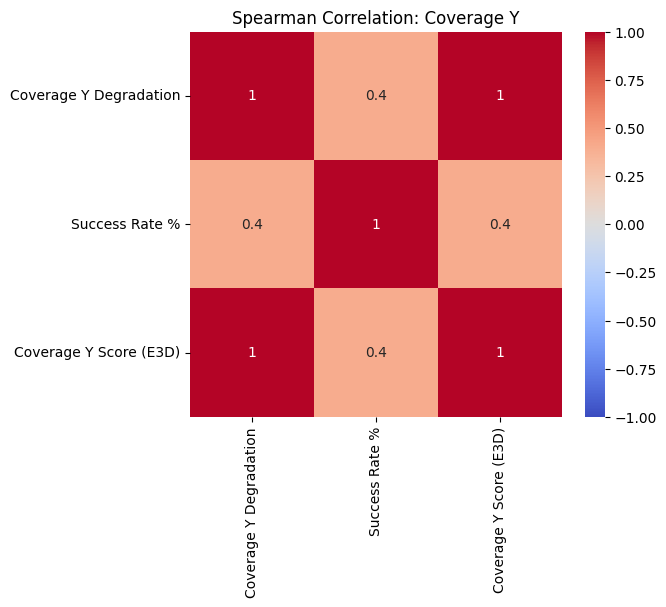


Spearman Correlation: Accuracy
                       Accuracy Degradation  Success Rate %  Accuracy (E3D)
Accuracy Degradation                   1.0            -1.0            -1.0
Success Rate %                        -1.0             1.0             1.0
Accuracy (E3D)                        -1.0             1.0             1.0


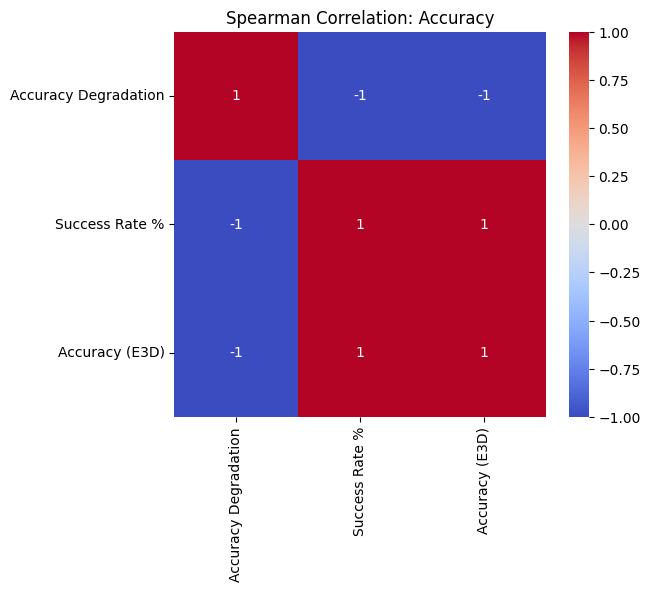


Spearman Correlation: Resolution
                         Resolution Degradation  Success Rate %  \
Resolution Degradation                     1.0            -0.8   
Success Rate %                            -0.8             1.0   
Resolution Score (E3D)                     1.0            -0.8   

                        Resolution Score (E3D)  
Resolution Degradation                     1.0  
Success Rate %                            -0.8  
Resolution Score (E3D)                     1.0  


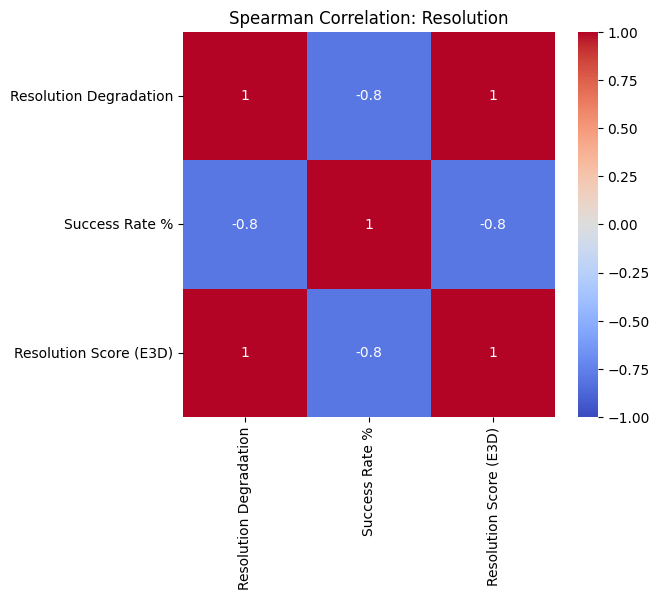

In [32]:
# %% Spearman heatmaps for 6 metrics using means_by_metric_intensity (from this notebook)
# and success rates parsed from a results .txt file.

import re, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# ---------------- CONFIG ----------------
success_txt_path = "./result-2.txt"  # <-- set to your file (e.g., "/mnt/data/result.txt")
# metrics_order = ["artifacts", "coverage_X", "coverage_Y", "coverage_Z", "accuracy", "resolution"]
metrics_order = ["artifacts", "coverage_X", "coverage_Y", "accuracy", "resolution"]
# Optional inversion (to match your earlier artifacts plot)
invert_degradation = {"artifacts": True, "coverage_X": False, "coverage_Y": False,
                      "coverage_Z": False, "accuracy": False, "resolution": False}

# ---------------- HELPERS ----------------
def to_float(s):
    try:
        return float(s)
    except Exception:
        return math.nan

def parse_success_txt(path):
    """
    Parse a results text like:
      Name:  25-..._artifact_0.005_0.02
      Success rate: 29.2
    Returns: dict[metric][intensity_key] = success_rate (float)
      metric ∈ {'artifacts','coverage_X','coverage_Y','coverage_Z','accuracy','resolution'}
      intensity_key:
         - artifacts, accuracy, resolution -> float (e.g., 0.005, 0.001, 0.2)
         - coverage axes -> "0.4_X", "0.5_Y", etc (string)
    """
    by_metric = {m: {} for m in metrics_order}

    # Regexes for the trailing part of "Name:"
    # artifact_<inten>_<...>
    re_art = re.compile(r".*_artifact_(?P<inten>\d+(?:\.\d+)?)(?:_\d+(?:\.\d+)?)?$", re.IGNORECASE)
    # coverage_<inten>_<axis>
    re_cov = re.compile(r".*_coverage_(?P<inten>\d+(?:\.\d+)?)[_-](?P<axis>[XYZ])$", re.IGNORECASE)
    # noise_<inten>  (maps to accuracy metric)
    re_acc = re.compile(r".*_noise_(?P<inten>\d+(?:\.\d+)?)$", re.IGNORECASE)
    # resolution_<inten>
    re_res = re.compile(r".*_resolution_(?P<inten>\d+(?:\.\d+)?)$", re.IGNORECASE)

    cur_key = None  # tuple: (metric, intensity_key)

    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if line.startswith("Name:"):
                name = line.split("Name:", 1)[1].strip()
                cur_key = None

                m = re_art.match(name)
                if m:
                    inten = to_float(m.group("inten"))
                    cur_key = ("artifacts", float(inten))

                else:
                    m = re_cov.match(name)
                    if m:
                        inten = to_float(m.group("inten"))
                        axis = m.group("axis").upper()
                        cur_key = (f"coverage_{axis}", f"{inten}_{axis}")

                    else:
                        m = re_acc.match(name)
                        if m:
                            inten = to_float(m.group("inten"))
                            cur_key = ("accuracy", float(inten))

                        else:
                            m = re_res.match(name)
                            if m:
                                inten = to_float(m.group("inten"))
                                cur_key = ("resolution", float(inten))

            elif cur_key and line.lower().startswith("success rate:"):
                val = line.split(":", 1)[1].strip()
                try:
                    sr = float(val)
                except Exception:
                    sr = math.nan
                metric, key = cur_key
                by_metric.setdefault(metric, {})[key] = sr
                cur_key = None  # consume once

    return by_metric

def sort_intensity_keys(keys):
    """
    Sort keys where keys can be floats or strings like '0.4_X'.
    """
    def kf(k):
        if isinstance(k, (int, float)):
            return (float(k), "")
        if isinstance(k, str) and "_" in k:
            num, axis = k.split("_", 1)
            try:
                return (float(num), axis)
            except Exception:
                return (num, axis)
        return (str(k), "")
    return sorted(keys, key=kf)

def make_corr_heatmap(df, title):
    corr_matrix = df.corr(method="spearman")
    print(f"\n{title}\n", corr_matrix)
    plt.figure(figsize=(6,5))
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title(title)
    plt.show()

# ---------------- MAIN ----------------
# 1) Parse success rates from the txt
success_by_metric = parse_success_txt(success_txt_path)

# 2) Build matrices per metric using means_by_metric_intensity (existing from earlier cell)
for metric in metrics_order:
    if metric not in means_by_metric_intensity:
        print(f"[WARN] No means_by_metric_intensity for metric '{metric}'. Skipping.")
        continue

    means_map = means_by_metric_intensity[metric]          # dict[intensity_key] -> mean over rounds
    success_map = success_by_metric.get(metric, {})        # dict[intensity_key] -> success rate

    # find overlap of intensity keys present in both
    common_keys = [k for k in sort_intensity_keys(means_map.keys()) if k in success_map]
    if not common_keys:
        print(f"[WARN] No overlapping intensities for metric '{metric}'. Skipping.")
        continue

    # Prepare arrays aligned by common_keys
    degr = []
    succ = []
    score = []

    for k in common_keys:
        # decode a numeric "degradation" value from the intensity key for plotting
        if isinstance(k, (int, float)):
            deg = float(k)
        else:
            # '0.4_X' -> numeric 0.4
            num = k.split("_", 1)[0]
            deg = float(num)

        # invert if requested (e.g., artifacts)
        if invert_degradation.get(metric, False):
            deg = 1.0 - deg

        degr.append(deg)
        succ.append(float(success_map[k]))
        score.append(float(means_map[k]))

    # Build DataFrame and plot
    pretty_metric = metric.replace("_", " ").title()
    score_label = "Accuracy (E3D)" if metric == "accuracy" else f"{pretty_metric} Score (E3D)"
    deg_label = f"{pretty_metric} Degradation"

    df = pd.DataFrame({
        deg_label: degr,
        "Success Rate %": succ,
        score_label: score
    })

    make_corr_heatmap(df, f"Spearman Correlation: {pretty_metric}")

/var/folders/0_/_7c36s_n19b660w201qjkgp00000gn/T/ipykernel_58676/1027794122.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar


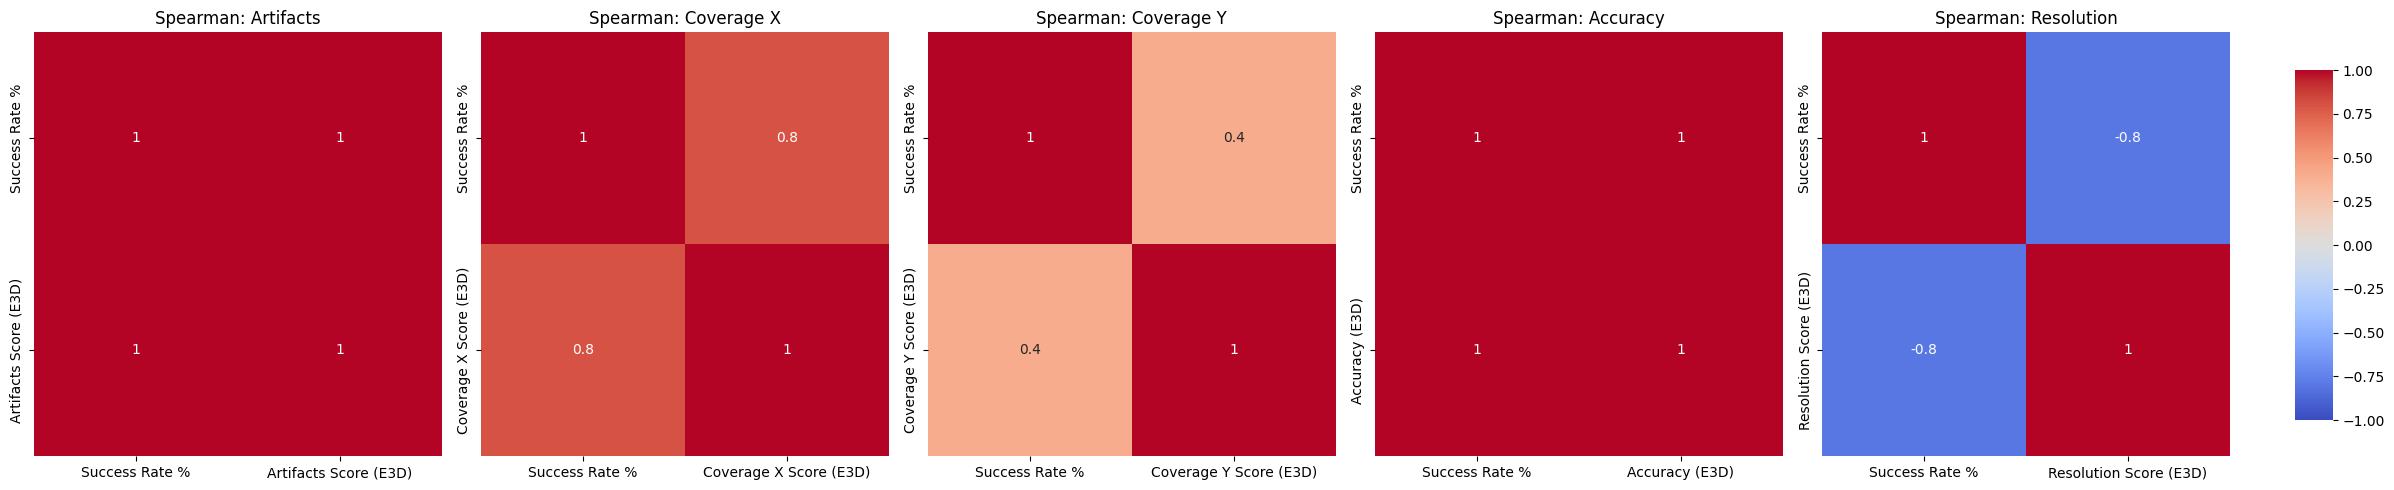

In [33]:
# %% Spearman heatmaps in a single 1x4 figure

import re, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------- CONFIG ----------------
success_txt_path = "./result-2.txt"  # <-- set your path
metrics_order = ["artifacts", "coverage_X", "coverage_Y", "accuracy", "resolution"]  # 5 provided
invert_degradation = {"artifacts": True, "coverage_X": False, "coverage_Y": False,
                      "coverage_Z": False, "accuracy": False, "resolution": False}

# ---------------- HELPERS ----------------
def to_float(s):
    try:
        return float(s)
    except Exception:
        return math.nan

def parse_success_txt(path):
    by_metric = {m: {} for m in metrics_order}
    re_art = re.compile(r".*_artifact_(?P<inten>\d+(?:\.\d+)?)(?:_\d+(?:\.\d+)?)?$", re.IGNORECASE)
    re_cov = re.compile(r".*_coverage_(?P<inten>\d+(?:\.\d+)?)[_-](?P<axis>[XYZ])$", re.IGNORECASE)
    re_acc = re.compile(r".*_noise_(?P<inten>\d+(?:\.\d+)?)$", re.IGNORECASE)     # noise -> accuracy
    re_res = re.compile(r".*_resolution_(?P<inten>\d+(?:\.\d+)?)$", re.IGNORECASE)

    cur_key = None
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if line.startswith("Name:"):
                name = line.split("Name:", 1)[1].strip()
                cur_key = None

                m = re_art.match(name)
                if m:
                    cur_key = ("artifacts", float(to_float(m.group("inten"))))
                else:
                    m = re_cov.match(name)
                    if m:
                        inten = float(to_float(m.group("inten")))
                        axis = m.group("axis").upper()
                        cur_key = (f"coverage_{axis}", f"{inten}_{axis}")
                    else:
                        m = re_acc.match(name)
                        if m:
                            cur_key = ("accuracy", float(to_float(m.group("inten"))))
                        else:
                            m = re_res.match(name)
                            if m:
                                cur_key = ("resolution", float(to_float(m.group("inten"))))
            elif cur_key and line.lower().startswith("success rate:"):
                val = line.split(":", 1)[1].strip()
                sr = to_float(val)
                metric, key = cur_key
                by_metric.setdefault(metric, {})[key] = sr
                cur_key = None
    return by_metric

def sort_intensity_keys(keys):
    def kf(k):
        if isinstance(k, (int, float)):
            return (float(k), "")
        if isinstance(k, str) and "_" in k:
            num, axis = k.split("_", 1)
            try:
                return (float(num), axis)
            except Exception:
                return (num, axis)
        return (str(k), "")
    return sorted(keys, key=kf)

# ---------------- MAIN ----------------
# Parse success rates
success_by_metric = parse_success_txt(success_txt_path)

# Build correlation matrices per metric using means_by_metric_intensity (must exist in notebook)
corr_items = []  # list of (title, corr_matrix)
for metric in metrics_order:
    if metric not in globals().get("means_by_metric_intensity", {}):
        continue
    means_map = means_by_metric_intensity[metric]
    success_map = success_by_metric.get(metric, {})

    # intersect intensity keys
    common_keys = [k for k in sort_intensity_keys(means_map.keys()) if k in success_map]
    if not common_keys:
        continue

    degr, succ, score = [], [], []
    for k in common_keys:
        if isinstance(k, (int, float)):
            deg = float(k)
        else:
            deg = float(k.split("_", 1)[0])  # '0.4_X' -> 0.4
        if invert_degradation.get(metric, False):
            deg = 1.0 - deg
        degr.append(deg)
        succ.append(float(success_map[k]))
        score.append(float(means_map[k]))

    pretty_metric = metric.replace("_", " ").title()
    score_label = "Accuracy (E3D)" if metric == "accuracy" else f"{pretty_metric} Score (E3D)"
    deg_label = f"{pretty_metric} Degradation"

    df = pd.DataFrame({
        # deg_label: degr,
        "Success Rate %": succ,
        score_label: score
    })
    corr_matrix = df.corr(method="spearman")
    corr_items.append((f"Spearman: {pretty_metric}", corr_matrix))

# Keep only first 4 to make a 1x4 layout
corr_items = corr_items[:5]

# Plot 1x4 with shared colorbar
n = len(corr_items)
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
if n < 5:
    # hide unused axes
    for ax in axes[n:]:
        ax.axis("off")

# Determine common color scale
vmin, vmax = -1, 1
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # colorbar axis

for i, (title, cm) in enumerate(corr_items):
    ax = axes[i]
    sns.heatmap(cm, annot=True, cmap="coolwarm", center=0, vmin=vmin, vmax=vmax,
                cbar=(i == n-1), cbar_ax=cbar_ax if i == n-1 else None, ax=ax)
    ax.set_title(title)

plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar
plt.show()